## Classifier

General idea : Predict the danger level of a circulation accident

In [177]:
import geopandas as gpd
import pandas as pd
import sklearn

In [178]:
df = gpd.read_file("data/accidents.shz")
df

,DATE,HEURE,CAUSE,TUES,BLESSES_GR,BLESSES_LE,DOMMAGES_M,METEO,ETAT_ROUTE,EMPLACEMEN,GENRE_ROUT,VITESSE_MA,LOCALITE,PRIORITE,ECLAIRAGE,LUMIERE,TRAFIC,GRAVITE_VA,TYPE_VALEU,TYPE_COMPL,geometry
0,20110102230000,18991230160000,manque d'égards en changeant de voie,0,0,0,3000,beau,sèche,giratoire,route principale,50.0,à l'intérieur d'une localité,aucune intersection,en service,aurore / crépuscule,normale,Dommages matériels,Accident lors de dépassement ou lors d'un chan...,Collision lors du changement de voie vers la g...,POINT (2570908 1162681)
1,20110104230000,18991230123500,inadaptée aux conditions de la route (mouillée...,0,0,0,1000,beau,verglacée,virage,route secondaire,80.0,à l'extérieur d'une localité,aucune intersection,aucun,jour,faible,Dommages matériels,Collision frontale,Frôlement avec le trafic venant en sens invers...,POINT (2568472 1166525)
2,20110104230000,18991230211500,"arrêt (freinage) sans raison sur la chaussée, ...",0,0,0,5000,couvert,sèche,ligne droite,route principale,50.0,à l'extérieur d'une localité,aucune intersection,en service,nuit,faible,Dommages matériels,Accident par tamponnement,Collision avec un véhicule en marche,POINT (2579634 1183736)
3,20110105230000,18991230063000,inadaptée aux conditions de la route (mouillée...,0,0,0,1500,pluie givrante,verglacée,virage,route secondaire,50.0,à l'intérieur d'une localité,aucune intersection,en service,aurore / crépuscule,faible,Dommages matériels,Dérapage ou perte de maîtrise,Collision avec un obstacle hors de la chaussée,POINT (2575732 1201401)
4,20110106230000,18991230161000,non-respect du signal de priorité «cédez le pa...,0,0,0,5000,couvert,humide,intersection,route principale,80.0,à l'extérieur d'une localité,signal «cédez le passage»,aucun,nuit,forte,Dommages matériels,Accident en s'engageant sur une route,Collision en obliquant à gauche avec le trafic...,POINT (2580788 1201641)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18586,20171024220000,18991230110000,autre attitude fautive lors des mouvements dan...,0,0,0,2000,beau,sèche,place de stationnement,autre,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,faible,Dommages matériels,Accident lors du stationnement,Avec violation de l'obligation de déclarer,POINT (2578230 1183912)
18587,20180107230000,18991230030000,présence d'animaux sauvages sur la chaussée,0,0,0,2000,couvert,sèche,ligne droite,autoroute,120.0,à l'extérieur d'une localité,aucune intersection,aucun,nuit,faible,Dommages matériels,Accident impliquant un animal,Collision avec du gibier (G),POINT (2559620 1153696)
18588,20230730220000,18991230114400,marche arrière imprudente,0,0,0,5000,beau,sèche,place de stationnement,autre,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,faible,Dommages matériels,Accident lors du stationnement,Collision avec un obstacle fixe (y compris véh...,POINT (2569312 1156707)
18589,20231107230000,18991230100000,cause inconnue,0,0,0,500,beau,sèche,giratoire,route principale,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,normale,Dommages matériels,Dérapage ou perte de maîtrise,Collision avec un autre usager (piéton y compris),POINT (2578217 1185451)


In [179]:
print(df.columns)
df.shape

Index(['DATE', 'HEURE', 'CAUSE', 'TUES', 'BLESSES_GR', 'BLESSES_LE',
       'DOMMAGES_M', 'METEO', 'ETAT_ROUTE', 'EMPLACEMEN', 'GENRE_ROUT',
       'VITESSE_MA', 'LOCALITE', 'PRIORITE', 'ECLAIRAGE', 'LUMIERE', 'TRAFIC',
       'GRAVITE_VA', 'TYPE_VALEU', 'TYPE_COMPL', 'geometry'],
      dtype='str')


(18591, 21)

In [180]:
df.dtypes

DATE               str
HEURE              str
CAUSE              str
TUES             int64
BLESSES_GR       int64
BLESSES_LE       int64
DOMMAGES_M       int64
METEO              str
ETAT_ROUTE         str
EMPLACEMEN         str
GENRE_ROUT         str
VITESSE_MA     float64
LOCALITE           str
PRIORITE           str
ECLAIRAGE          str
LUMIERE            str
TRAFIC             str
GRAVITE_VA         str
TYPE_VALEU         str
TYPE_COMPL         str
geometry      geometry
dtype: object

In [181]:
df.isna().sum()
df.dropna(inplace=True)
df.isna().sum()

DATE          0
HEURE         0
CAUSE         0
TUES          0
BLESSES_GR    0
BLESSES_LE    0
DOMMAGES_M    0
METEO         0
ETAT_ROUTE    0
EMPLACEMEN    0
GENRE_ROUT    0
VITESSE_MA    0
LOCALITE      0
PRIORITE      0
ECLAIRAGE     0
LUMIERE       0
TRAFIC        0
GRAVITE_VA    0
TYPE_VALEU    0
TYPE_COMPL    0
geometry      0
dtype: int64

In [182]:

#Drop columns with informations we could not get
#TODO : SEE AGAINM WHICH COLUMNS TO DROP; MIGHT BE KEEP SOME OF THEM BY USING THE INFOS OF RETRANSCRIPTION ?
COLUMNS_TO_DROP = ['DOMMAGES_M', 'PRIORITE', 'TYPE_VALEU', 'TYPE_COMPL', 'GRAVITE_VA']

if all(col in df.columns for col in COLUMNS_TO_DROP):
    df.drop(columns=COLUMNS_TO_DROP, inplace=True)

df.describe()


,TUES,BLESSES_GR,BLESSES_LE,VITESSE_MA
count,14311.000000,14311.000000,14311.000000,14311.000000
mean,0.009573,0.146111,0.589896,64.471595
std,0.107603,0.389187,0.796046,23.553644
min,0.000000,0.000000,0.000000,5.000000
25%,0.000000,0.000000,0.000000,50.000000
50%,0.000000,0.000000,0.000000,50.000000
75%,0.000000,0.000000,1.000000,80.000000
max,4.000000,5.000000,15.000000,120.000000


In [183]:
#get unique values for each column
#REMOVED FROM THE LIST : 'ETAT_ROUTE', 'PRIORITE', 'ECLAIRAGE', , 'TYPE_VALEU', 'TYPE_COMPL', 'GRAVITE_VA'
UNIQUE_COLUMNS_TO_CHECK = ['METEO', 'EMPLACEMEN', 'GENRE_ROUT', 'LOCALITE',  'ECLAIRAGE', 'LUMIERE', 'TRAFIC', 'ETAT_ROUTE']
for col in UNIQUE_COLUMNS_TO_CHECK:
    print(f"Unique values for column {col}: {df[col].unique()}\n")

Unique values for column METEO: <StringArray>
[          'beau',        'couvert', 'pluie givrante',          'autre',
          'pluie', 'chute de neige',          'grêle']
Length: 7, dtype: str

Unique values for column EMPLACEMEN: <StringArray>
[             'giratoire',                 'virage',           'ligne droite',
           'intersection', 'place de stationnement',                  'place',
                  'autre',          'aire de repos']
Length: 8, dtype: str

Unique values for column GENRE_ROUT: <StringArray>
[                 'route principale',                  'route secondaire',
                         'autoroute',                             'autre',
 'installation annexe sur autoroute',                    'semi-autoroute']
Length: 6, dtype: str

Unique values for column LOCALITE: <StringArray>
['à l'intérieur d'une localité', 'à l'extérieur d'une localité']
Length: 2, dtype: str

Unique values for column ECLAIRAGE: <StringArray>
['en service', 'aucun', 'hors se

In [ ]:
from sklearn.preprocessing import OneHotEncoder
#convert date to datetime
df_cleaned = df.copy()
df_cleaned['DATE'] = pd.to_datetime(df['DATE'].str[:8], format='%Y%m%d')
heure_str = df['HEURE'].str[-6:]
df_cleaned['HEURE'] = pd.to_datetime(heure_str, format='%H%M%S').dt.hour
print(df_cleaned['HEURE'].head())


df_cleaned.drop(columns=['DATE', 'CAUSE'], inplace=True)

categorical_cols = df_cleaned.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_features = encoder.fit_transform(df_cleaned[categorical_cols])

encoded_df = pd.DataFrame(
    encoded_features, 
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df_cleaned.index
)

df_final = pd.concat([df_cleaned.drop(columns=categorical_cols), encoded_df], axis=1)
df_final.loc[df_final['TUES'] >= 1, 'TUES'] = 1
df_final.loc[df_final['BLESSES_LE'] >= 1, 'BLESSES_LE'] = 1
df_final.loc[df_final['BLESSES_GR'] >= 1, 'BLESSES_GR'] = 1
df_final.describe()


0    16:00:00
1    12:35:00
2    21:15:00
3    06:30:00
4    16:10:00
Name: HEURE, dtype: object


C:\Users\gaeta\AppData\Local\Temp\ipykernel_51952\3171133738.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_cleaned.select_dtypes(include=['object']).columns


,TUES,BLESSES_GR,BLESSES_LE,VITESSE_MA,HEURE_00:03:00,HEURE_00:05:00,HEURE_00:06:00,HEURE_00:08:00,HEURE_00:10:00,HEURE_00:11:00,HEURE_00:13:00,HEURE_00:15:00,HEURE_00:19:00,HEURE_00:20:00,HEURE_00:24:00,HEURE_00:25:00,HEURE_00:26:00,HEURE_00:30:00,HEURE_00:31:00,HEURE_00:35:00,HEURE_00:40:00,HEURE_00:45:00,HEURE_00:47:00,HEURE_00:48:00,HEURE_00:50:00,HEURE_00:55:00,HEURE_00:56:00,HEURE_00:58:00,HEURE_01:00:00,HEURE_01:01:00,HEURE_01:05:00,HEURE_01:10:00,HEURE_01:14:00,HEURE_01:15:00,HEURE_01:17:00,HEURE_01:20:00,HEURE_01:23:00,HEURE_01:24:00,HEURE_01:25:00,HEURE_01:27:00,...,HEURE_23:35:00,HEURE_23:40:00,HEURE_23:44:00,HEURE_23:45:00,HEURE_23:50:00,HEURE_23:55:00,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,METEO_pluie givrante,ETAT_ROUTE_humide,ETAT_ROUTE_mouillé,ETAT_ROUTE_route enneigée,ETAT_ROUTE_sèche,ETAT_ROUTE_verglacée,EMPLACEMEN_autre,EMPLACEMEN_giratoire,EMPLACEMEN_intersection,EMPLACEMEN_ligne droite,EMPLACEMEN_place,EMPLACEMEN_place de stationnement,EMPLACEMEN_virage,GENRE_ROUT_autre,GENRE_ROUT_installation annexe sur autoroute,GENRE_ROUT_route principale,GENRE_ROUT_route secondaire,GENRE_ROUT_semi-autoroute,LOCALITE_à l'intérieur d'une localité,ECLAIRAGE_en service,ECLAIRAGE_hors service,LUMIERE_inconnu,LUMIERE_jour,LUMIERE_nuit,TRAFIC_faible,TRAFIC_file arrêtée,TRAFIC_file ralentie,TRAFIC_forte,TRAFIC_normale
count,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,...,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000
mean,0.008804,0.135281,0.464817,64.471595,0.000070,0.000559,0.000070,0.000070,0.001258,0.000070,0.000070,0.002026,0.000070,0.000839,0.000070,0.000699,0.000070,0.001747,0.000070,0.000629,0.000629,0.001537,0.000070,0.000140,0.000769,0.000629,0.000070,0.000070,0.002516,0.000070,0.000699,0.000699,0.000070,0.001467,0.000070,0.001048,0.000070,0.000070,0.000489,0.000070,...,0.000489,0.001188,0.000070,0.000839,0.001048,0.000559,0.620292,0.031584,0.228496,0.001887,0.096359,0.001747,0.092726,0.125847,0.032003,0.723849,0.017329,0.006778,0.074628,0.147509,0.499895,0.012158,0.054224,0.204248,0.069457,0.001607,0.559639,0.246733,0.010481,0.560129,0.183216,0.241842,0.002446,0.662777,0.256656,0.433722,0.011949,0.018797,0.109077,0.418909
std,0.093421,0.342035,0.498778,23.553644,0.008359,0.023638,0.008359,0.008359,0.035444,0.008359,0.008359,0.044972,0.008359,0.028946,0.008359,0.026426,0.008359,0.041761,0.008359,0.025071,0.025071,0.039179,0.008359,0.011821,0.027715,0.025071,0.008359,0.008359,0.050094,0.008359,0.026426,0.026426,0.008359,0.038280,0.008359,0.032359,0.008359,0.008359,0.022112,0.008359,...,0.022112,0.034447,0.008359,0.028946,0.032359,0.023638,0.485331,0.174896,0.419878,0.043396,0.295094,0.041761,0.290058,0.331689,0.176015,0.447108,0.130500,0.082052,0.262799,0.354625,0.500017,0.109597,0.226467,0.403165,0.254239,0.040059,0.496448,0.431125,0.101845,0.496389,0.386857,0.428214,0.049395,0.472778,0.436803,0.495605,0.108660,0.135811,0.311747,0.493398
min,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000

In [185]:
#TODO: SEE IF WE COULD KEEP IT FOR FURTHER VISUALIZATION....
df_final.drop('geometry', inplace=True, axis=1)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sélectionner toutes les lignes (variables) et les 3 premières colonnes
corr_subset = df_final.corr().iloc[:, :3]

# Création de la figure
plt.figure(figsize=(8, 10)) # Ajuste la taille selon le nombre total de variables
sns.heatmap(
    corr_subset, 
    annot=True,       # Affiche les valeurs numériques dans les cases
    cmap="coolwarm",  # Palette de couleurs (bleu = négatif, rouge = positif)
    fmt=".2f",        # Format des nombres (2 décimales)
    linewidths=0.5,   # Lignes de séparation entre les cellules
    cbar=True         # Barre de couleur sur le côté
)

plt.title("Corrélation des 3 premières colonnes avec toutes les autres", fontsize=12)
plt.xlabel("3 premières colonnes")
plt.ylabel("Toutes les variables")
plt.show()

In [ ]:
#train_val_test split
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

X_train, X_test, y_train, y_test = train_test_split(df_final.drop(columns=['TUES','BLESSES_GR','BLESSES_LE']), df_final[['TUES', 'BLESSES_GR', 'BLESSES_LE']], test_size=0.4, random_state=42)

tues_train = y_train['TUES']
graves_train = y_train['BLESSES_GR']
legers_train = y_train['BLESSES_LE']

total_tues = tues_train.sum()
total_graves = graves_train.sum()
total_legers = legers_train.sum()
total_accidents = total_tues + total_graves + total_legers

ratio_leger = total_legers / total_accidents+1e-6
ratio_grave = total_graves / total_accidents+1e-6
ratio_tue = total_tues / total_accidents+1e-6

print(f"RATIO LEGERS : {ratio_leger}")
print(f"RATIO GRAVES : {ratio_grave}")
print(f"RATIO TUES : {ratio_tue}")

sample_weights = (
    1.0
    + (y_train['BLESSES_LE'] * ratio_leger)
    + (y_train['BLESSES_GR'] * ratio_grave)
    + (y_train['TUES'] * ratio_tue)
)


RATIO LEGERS : 0.764673256097561
RATIO GRAVES : 0.22103758536585366
RATIO TUES : 0.014292158536585366


In [ ]:
from sklearn.model_selection import GridSearchCV

def find_best_hyperparameters(regressor, param_grid, X_train, y_train, scoring = 'r2', sample_weights = None):
    grid_search = GridSearchCV(regressor, param_grid, cv=5, scoring=scoring, return_train_score=True, n_jobs=-1, verbose=2) # use all the cores of the CPU
    grid_search.fit(X_train, y_train, sample_weight=sample_weights)
    print("Best hyperparameters: {}".format(grid_search.best_params_))
    print("Best score (r2): {:.2f}".format(grid_search.best_score_))
    return grid_search.best_estimator_

In [ ]:
from sklearn.model_selection import cross_validate
def print_cross_validation_results(regressor, X_train, y_train):
    scoring = ['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']
    cv_results = cross_validate(regressor, X_train, y_train, cv=5, scoring = scoring, n_jobs=-1, return_train_score=True)
    print("Train R^2: {:.2f}".format(cv_results['train_r2'].mean()))
    print("Validation R^2: {:.2f}".format(cv_results['test_r2'].mean()))
    print("Train MAE: {:.2f}".format(-cv_results['train_neg_mean_absolute_error'].mean()))
    print("Validation MAE: {:.2f}".format(-cv_results['test_neg_mean_absolute_error'].mean()))
    print("Train RMSE: {:.2f}".format(-cv_results['train_neg_root_mean_squared_error'].mean()))
    print("Validation RMSE: {:.2f}".format(-cv_results['test_neg_root_mean_squared_error'].mean()))

In [ ]:
# from sklearn.ensemble import RandomForestRegressor

# param_grid = {'n_estimators': [10, 100], 'max_depth': [None, 1, 3,5, 10, 20], 'min_samples_split': [2, 4,8,16, 32], 'min_samples_leaf': [1,2,3,4, 8 ,16]}

# rf_reg = RandomForestRegressor()

# rf_reg = find_best_hyperparameters(rf_reg, param_grid, X_train, y_train, sample_weights=sample_weights)

# print_cross_validation_results(rf_reg, X_train, y_train)

In [ ]:
import numpy as np

print("Total accidents by class")
print("Tué: ", df_final['TUES'].sum())
print("Grave: ", df_final['BLESSES_GR'].sum())
print("Leger: ", df_final['BLESSES_LE'].sum(), "\n")

#IT'S ORDERED BTW
conditions = [
    (df_final['TUES'] > 0),
    (df_final['BLESSES_GR'] > 0),
    (df_final['BLESSES_LE'] > 0)
]

choices = [3, 2, 1]

#0 if no victime of any sort
df_final['VICTIME'] = np.select(conditions, choices, default=0)
df_final.drop(columns=['TUES','BLESSES_GR','BLESSES_LE'], inplace=True)
print(df_final['VICTIME'].value_counts())

df_final.describe()

Total accidents by class
Tué:  126
Grave:  1936
Leger:  6652 

VICTIME
1    6287
0    5981
2    1917
3     126
Name: count, dtype: int64


,VITESSE_MA,HEURE_00:03:00,HEURE_00:05:00,HEURE_00:06:00,HEURE_00:08:00,HEURE_00:10:00,HEURE_00:11:00,HEURE_00:13:00,HEURE_00:15:00,HEURE_00:19:00,HEURE_00:20:00,HEURE_00:24:00,HEURE_00:25:00,HEURE_00:26:00,HEURE_00:30:00,HEURE_00:31:00,HEURE_00:35:00,HEURE_00:40:00,HEURE_00:45:00,HEURE_00:47:00,HEURE_00:48:00,HEURE_00:50:00,HEURE_00:55:00,HEURE_00:56:00,HEURE_00:58:00,HEURE_01:00:00,HEURE_01:01:00,HEURE_01:05:00,HEURE_01:10:00,HEURE_01:14:00,HEURE_01:15:00,HEURE_01:17:00,HEURE_01:20:00,HEURE_01:23:00,HEURE_01:24:00,HEURE_01:25:00,HEURE_01:27:00,HEURE_01:30:00,HEURE_01:35:00,HEURE_01:40:00,...,HEURE_23:40:00,HEURE_23:44:00,HEURE_23:45:00,HEURE_23:50:00,HEURE_23:55:00,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,METEO_pluie givrante,ETAT_ROUTE_humide,ETAT_ROUTE_mouillé,ETAT_ROUTE_route enneigée,ETAT_ROUTE_sèche,ETAT_ROUTE_verglacée,EMPLACEMEN_autre,EMPLACEMEN_giratoire,EMPLACEMEN_intersection,EMPLACEMEN_ligne droite,EMPLACEMEN_place,EMPLACEMEN_place de stationnement,EMPLACEMEN_virage,GENRE_ROUT_autre,GENRE_ROUT_installation annexe sur autoroute,GENRE_ROUT_route principale,GENRE_ROUT_route secondaire,GENRE_ROUT_semi-autoroute,LOCALITE_à l'intérieur d'une localité,ECLAIRAGE_en service,ECLAIRAGE_hors service,LUMIERE_inconnu,LUMIERE_jour,LUMIERE_nuit,TRAFIC_faible,TRAFIC_file arrêtée,TRAFIC_file ralentie,TRAFIC_forte,TRAFIC_normale,VICTIME
count,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,...,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000
mean,64.471595,0.000070,0.000559,0.000070,0.000070,0.001258,0.000070,0.000070,0.002026,0.000070,0.000839,0.000070,0.000699,0.000070,0.001747,0.000070,0.000629,0.000629,0.001537,0.000070,0.000140,0.000769,0.000629,0.000070,0.000070,0.002516,0.000070,0.000699,0.000699,0.000070,0.001467,0.000070,0.001048,0.000070,0.000070,0.000489,0.000070,0.001747,0.000908,0.000769,...,0.001188,0.000070,0.000839,0.001048,0.000559,0.620292,0.031584,0.228496,0.001887,0.096359,0.001747,0.092726,0.125847,0.032003,0.723849,0.017329,0.006778,0.074628,0.147509,0.499895,0.012158,0.054224,0.204248,0.069457,0.001607,0.559639,0.246733,0.010481,0.560129,0.183216,0.241842,0.002446,0.662777,0.256656,0.433722,0.011949,0.018797,0.109077,0.418909,0.733631
std,23.553644,0.008359,0.023638,0.008359,0.008359,0.035444,0.008359,0.008359,0.044972,0.008359,0.028946,0.008359,0.026426,0.008359,0.041761,0.008359,0.025071,0.025071,0.039179,0.008359,0.011821,0.027715,0.025071,0.008359,0.008359,0.050094,0.008359,0.026426,0.026426,0.008359,0.038280,0.008359,0.032359,0.008359,0.008359,0.022112,0.008359,0.041761,0.030127,0.027715,...,0.034447,0.008359,0.028946,0.032359,0.023638,0.485331,0.174896,0.419878,0.043396,0.295094,0.041761,0.290058,0.331689,0.176015,0.447108,0.130500,0.082052,0.262799,0.354625,0.500017,0.109597,0.226467,0.403165,0.254239,0.040059,0.496448,0.431125,0.101845,0.496389,0.386857,0.428214,0.049395,0.472778,0.436803,0.495605,0.108660,0.135811,0.311747,0.493398,0.718460
min,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

X_train, X_test, y_train, y_test = train_test_split(df_final.drop(columns=['VICTIME']), df_final[['VICTIME']], test_size=0.4, random_state=42)


param_grid = {'n_estimators': [10, 100, 1000], 'learning_rate': [0.1, 0.05, 0.01, 0.001]}

clf = GradientBoostingRegressor(n_estimators=100, learning_rate=1.0,max_depth=1, random_state=0)

clf = find_best_hyperparameters(clf, param_grid, X_train, y_train, sample_weights=sample_weights)
print_cross_validation_results(clf, X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


KeyboardInterrupt: 

tensor([ 1.0000,  1.3077,  4.5241, 69.9684])
Epoch 1, Loss: 1.542487621307373
Epoch 2, Loss: 1.5076745748519897
Epoch 3, Loss: 1.4611624479293823
Epoch 4, Loss: 1.4232940673828125
Epoch 5, Loss: 1.3998667001724243
Epoch 6, Loss: 1.38933527469635
Epoch 7, Loss: 1.3897539377212524
Epoch 8, Loss: 1.3974791765213013
Epoch 9, Loss: 1.4082045555114746
Epoch 10, Loss: 1.4172594547271729
Epoch 11, Loss: 1.420723795890808
Epoch 12, Loss: 1.4179718494415283
Epoch 13, Loss: 1.4108821153640747
Epoch 14, Loss: 1.4018925428390503
Epoch 15, Loss: 1.3927898406982422
Epoch 16, Loss: 1.3848811388015747
Epoch 17, Loss: 1.3794662952423096
Epoch 18, Loss: 1.3776273727416992
Epoch 19, Loss: 1.379442572593689
Epoch 20, Loss: 1.383468747138977
Epoch 21, Loss: 1.387344479560852
Epoch 22, Loss: 1.3891878128051758
Epoch 23, Loss: 1.388609766960144
Epoch 24, Loss: 1.3865171670913696
Epoch 25, Loss: 1.3841361999511719
Epoch 26, Loss: 1.3821496963500977
Epoch 27, Loss: 1.38059663772583
Epoch 28, Loss: 1.37928962707

array([1, 0, 1, 2, 0])

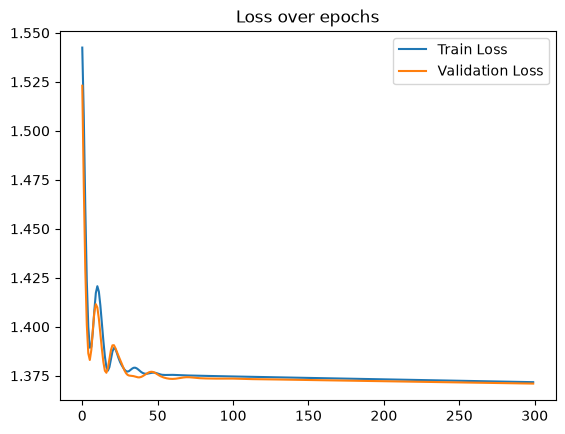

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

X_train, X_temp, y_train, y_temp = train_test_split(df_final.drop(columns=['VICTIME']), df_final[['VICTIME']], test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

X_train = torch.tensor(X_train.values, dtype=torch.float32)
X_val = torch.tensor(X_val.values, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long).squeeze()
y_val = torch.tensor(y_val.values, dtype=torch.long).squeeze()

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 4)
)

print(weights := torch.tensor([1.0, 1/ratio_leger, 1/ratio_grave, 1/ratio_tue], dtype=torch.float32))

loss_fct = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 1/ratio_leger, 1/ratio_grave, 1/ratio_tue], dtype=torch.float32))
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

train, val = [], []

for epoch in range(300):
    outputs = model(X_train)
    # print(f"Epoch {epoch+1}, Outputs: {outputs}")
    loss = loss_fct(outputs, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train.append(loss.item())
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = loss_fct(val_outputs, y_val)
        val.append(val_loss.item())
    print(f"Epoch {epoch+1}, Loss: {loss.item()}")

plt.plot(train, label='Train Loss')
plt.plot(val, label='Validation Loss')
plt.legend()
plt.title('Loss over epochs')

model.eval()

with torch.no_grad():
    val_outputs = model(X_val)
    
    probabilities = torch.softmax(val_outputs, dim=1)
    
    max_probs, predicted = torch.max(probabilities, dim=1)

for i in range(5):
    print(f"Accident {i} -> Classe prédite : {predicted[i].item()} (Confiance : {max_probs[i].item() * 100:.1f}%)", probabilities[i].numpy())

accuracy = (predicted == y_val).sum().item() / y_val.size(0)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

y_val_np = y_val.numpy()
y_val_np[:5]
